# Error Analysis: Word Sense Disambiguation

Analyzing prediction errors from **E5-large + Weighted Def + Examples** to identify failure patterns and improvement opportunities.

In [ ]:
from pathlib import Path
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 200)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Paths
predictions_path = Path('../../data/evaluation/atemporal/results/predictions.csv')
words_path = Path('../../data/evaluation/atemporal/input/words.csv')
senses_path = Path('../../data/evaluation/atemporal/input/sense_text_representations.jsonl')

In [2]:
# Load all data
df = pd.read_csv(predictions_path)
words_df = pd.read_csv(words_path)
senses_df = pd.read_json(senses_path, lines=True)

# Merge polysemy info
df = df.merge(words_df[['lemma', 'n_senses', 'polysemy_category']], on='lemma', how='left')

# Create sense lookup for readable names
sense_lookup = senses_df.set_index('synset_id')[['lemma', 'class', 'baseline']].to_dict('index')

def get_sense_info(sense_id):
    if sense_id in sense_lookup:
        info = sense_lookup[sense_id]
        return f"{info['class']}"
    return sense_id

df['gold_class'] = df['gold_sense'].apply(get_sense_info)
df['pred_class'] = df['pred_sense'].apply(get_sense_info)

print(f"Loaded {len(df)} predictions across {df['lemma'].nunique()} lemmas")

Loaded 93 predictions across 10 lemmas


## 1. Overview

In [3]:
accuracy = df['correct'].mean()
n_correct = df['correct'].sum()
n_errors = (~df['correct']).sum()
n_total = len(df)

# Rank distribution
rank_1 = (df['gold_rank'] == 1).sum()
rank_2 = (df['gold_rank'] == 2).sum()
rank_3 = (df['gold_rank'] == 3).sum()
rank_4plus = (df['gold_rank'] >= 4).sum()

summary_df = pd.DataFrame(
    {
        'Metric': ['Accuracy', 'Correct', 'Errors', 'Total'],
        'Value': [f"{accuracy:.1%}", n_correct, n_errors, n_total],
    }
)

rank_df = pd.DataFrame(
    {
        'Gold Rank': ['1 (correct)', '2 (near miss)', '3', '4+'],
        'Count': [rank_1, rank_2, rank_3, rank_4plus],
    }
)

display(Markdown("### Prediction Summary"))
display(
    summary_df.style.set_properties(**{'text-align': 'center'}).set_table_styles(
        [
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#f2f2f2'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '8px'),
                ],
            },
            {'selector': 'td', 'props': [('padding', '6px')]},
        ]
    )
)

display(Markdown("### Gold Rank Distribution"))
display(
    rank_df.style.set_properties(**{'text-align': 'center'}).set_table_styles(
        [
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#f2f2f2'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '8px'),
                ],
            },
            {'selector': 'td', 'props': [('padding', '6px')]},
        ]
    )
)


### Prediction Summary

,Metric,Value
0,Accuracy,54.8%
1,Correct,51
2,Errors,42
3,Total,93


### Gold Rank Distribution

,Gold Rank,Count
0,1 (correct),51
1,2 (near miss),17
2,3,22
3,4+,3


## 2. Performance by Lemma

,lemma,polysemy_category,n_senses,count,correct,errors,accuracy
2,Doktor,low,3,10,1,9,10.0%
0,Antwort,low,2,7,1,6,14.3%
1,Bahn,high,7,10,4,6,40.0%
8,springen,medium,6,10,4,6,40.0%
5,bitter,medium,4,10,6,4,60.0%
6,hören,high,8,8,5,3,62.5%
7,sitzen,high,7,9,6,3,66.7%
4,Schatz,medium,4,10,8,2,80.0%
9,wagen,low,3,10,8,2,80.0%
3,Glas,medium,4,9,8,1,88.9%


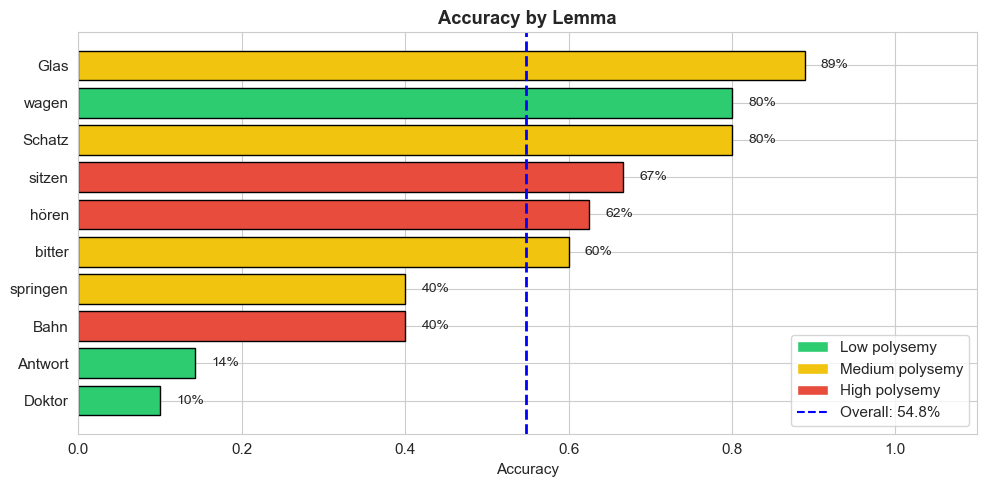

In [4]:
# Per-lemma breakdown with polysemy info
by_lemma = df.groupby(['lemma', 'n_senses', 'polysemy_category']).agg(
    count=('correct', 'count'),
    correct=('correct', 'sum'),
    accuracy=('correct', 'mean')
).reset_index().sort_values('accuracy')

by_lemma['errors'] = by_lemma['count'] - by_lemma['correct']

# Styled table
styled = by_lemma[['lemma', 'polysemy_category', 'n_senses', 'count', 'correct', 'errors', 'accuracy']].style.format({
    'accuracy': '{:.1%}',
}).background_gradient(
    subset=['accuracy'], cmap='RdYlGn', vmin=0, vmax=1
).set_properties(**{
    'text-align': 'center',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
]).set_caption("📊 Accuracy by Lemma (sorted worst → best)")

display(styled)

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
colors = {'low': '#2ecc71', 'medium': '#f1c40f', 'high': '#e74c3c'}
bar_colors = [colors.get(p, '#95a5a6') for p in by_lemma['polysemy_category']]

bars = ax.barh(by_lemma['lemma'], by_lemma['accuracy'], color=bar_colors, edgecolor='black', linewidth=1)
ax.axvline(x=accuracy, color='blue', linestyle='--', linewidth=2, label=f'Overall: {accuracy:.1%}')

for bar, acc in zip(bars, by_lemma['accuracy']):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2, f'{acc:.0%}', va='center', fontsize=10)

ax.set_xlabel('Accuracy')
ax.set_xlim(0, 1.1)
ax.set_title('Accuracy by Lemma', fontweight='bold')
ax.legend(loc='lower right')

# Legend for polysemy
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors['low'], label='Low polysemy'),
                   Patch(facecolor=colors['medium'], label='Medium polysemy'),
                   Patch(facecolor=colors['high'], label='High polysemy')]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color='blue', linestyle='--', label=f'Overall: {accuracy:.1%}')], 
          loc='lower right')

plt.tight_layout()
plt.show()

## 3. Accuracy by Polysemy Level

In [5]:
# By polysemy category
by_polysemy = df.groupby('polysemy_category').agg(
    lemmas=('lemma', 'nunique'),
    instances=('correct', 'count'),
    correct=('correct', 'sum'),
    accuracy=('correct', 'mean'),
    avg_senses=('n_senses', 'mean')
).reindex(['low', 'medium', 'high'])

by_polysemy['errors'] = by_polysemy['instances'] - by_polysemy['correct']

display(Markdown("### Performance by Polysemy Level"))

styled = by_polysemy.style.format({
    'accuracy': '{:.1%}',
    'avg_senses': '{:.1f}'
}).background_gradient(
    subset=['accuracy'], cmap='RdYlGn', vmin=0.3, vmax=0.8
).set_properties(**{
    'text-align': 'center',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
])

display(styled)


### Performance by Polysemy Level

,lemmas,instances,correct,accuracy,avg_senses,errors
polysemy_category,,,,,,
low,3,27,10,37.0%,2.7,17
medium,4,39,26,66.7%,4.5,13
high,3,27,15,55.6%,7.3,12


## 4. Hardest Cases: Worst Lemmas Deep Dive

In [6]:
# Focus on the 2 worst-performing lemmas
worst_lemmas = by_lemma.head(2)['lemma'].tolist()

display(Markdown("### Worst-Performing Lemmas"))

for lemma in worst_lemmas:
    lemma_df = df[df['lemma'] == lemma]
    lemma_acc = lemma_df['correct'].mean()
    n_senses = lemma_df['n_senses'].iloc[0]
    
    display(Markdown(f"**{lemma}** — {lemma_acc:.0%} accuracy ({n_senses} senses)"))
    
    # Confusion matrix for this lemma
    lemma_errors = lemma_df[~lemma_df['correct']]
    if len(lemma_errors) > 0:
        conf = pd.crosstab(lemma_errors['gold_class'], lemma_errors['pred_class'], margins=True)
        display(Markdown("Confusion matrix (errors only): rows=gold, cols=predicted"))
        display(conf)
    
    # Show example errors
    display(Markdown("Example errors:"))
    examples = lemma_errors[['sentence', 'gold_class', 'pred_class', 'gold_rank']].head(3)
    display(examples.style.set_properties(**{'text-align': 'left'}))


### Worst-Performing Lemmas

**Doktor** — 10% accuracy (3 senses)

Confusion matrix (errors only): rows=gold, cols=predicted

pred_class,Mensch,All
gold_class,,
Kommunikation,9,9
All,9,9


Example errors:

...

**Antwort** — 14% accuracy (2 senses)

Confusion matrix (errors only): rows=gold, cols=predicted

pred_class,Geschehen,All
gold_class,,
Kommunikation,6,6
All,6,6


Example errors:

,sentence,gold_class,pred_class,gold_rank
10,Eine ausführliche griechische Antwort solle nach einer genaueren Prüfung der sowjetischen Note gegeben werden.,Kommunikation,Geschehen,2
11,Sie selbst müssen auf die vielen Fragen Antworten finden.,Kommunikation,Geschehen,2
13,"Es geht eben hart auf hart, war schließlich seine letzte Antwort.",Kommunikation,Geschehen,2


## 5. Near-Miss Analysis (Rank 2 Errors)

In [8]:
# Near-misses: gold was ranked #2
near_misses = df[df['gold_rank'] == 2].copy()
n_near = len(near_misses)
pct_near = n_near / n_errors * 100 if n_errors > 0 else 0

display(Markdown(
    f"### Near Misses"
    f"{n_near} errors ({pct_near:.0f}% of all errors). Gold was ranked #2."
))

if len(near_misses) > 0:
    display(Markdown("Near-miss examples:"))
    near_examples = near_misses[['lemma', 'sentence', 'gold_class', 'pred_class']].head(5)
    display(near_examples.style.set_properties(**{'text-align': 'left', 'font-size': '10pt'}))


### Near Misses17 errors (40% of all errors). Gold was ranked #2.

Near-miss examples:

,lemma,sentence,gold_class,pred_class
3,Doktor,Ein paar schöne Medaillen verdankt das Kaiser Friedrich-Museum Herrn Dr. James Simon.,Kommunikation,Mensch
10,Antwort,Eine ausführliche griechische Antwort solle nach einer genaueren Prüfung der sowjetischen Note gegeben werden.,Kommunikation,Geschehen
11,Antwort,Sie selbst müssen auf die vielen Fragen Antworten finden.,Kommunikation,Geschehen
13,Antwort,"Es geht eben hart auf hart, war schließlich seine letzte Antwort.",Kommunikation,Geschehen
14,Antwort,Diese Antwort vom 26. November 1941 sei sodann von den Japanern und später auch von politischen Kreisen in den Vereinigten Staaten völlig unzutreffenderweise als Ultimatum bezeichnet worden.,Kommunikation,Geschehen


## 6. Key Takeaways

Based on this error analysis:

1. **Hardest lemmas**: Check which words have systematically low accuracy
2. **Near-misses**: A high proportion of rank-2 errors suggests the model is "close" but needs better disambiguation
3. **Polysemy effect**: Whether high-polysemy words are harder can inform whether to focus on fine-grained sense distinctions
4. **Sense confusions**: Specific sense pairs that get confused may need better example sentences or definitions